# A Machine Learning–Driven Predictive and Prescriptive Analytics Framework for Forecasting Weekly Production Target Achievement in the Shoe Manufacturing Division of Ceylon Leather Products Manufacturers Ltd (DI Leather)

## Exploratory Data Analysis (EDA)

This notebook performs a comprehensive Exploratory Data Analysis (EDA) of the DI Leather weekly production performance dataset.

The purpose of this EDA is to understand the structure, quality, distribution, temporal patterns, categorical characteristics, and numerical relationships within the production data before developing a machine learning model.

For the revised modelling approach, **Actual Quantity (`actual_qty`) is selected as the target variable**.

The machine learning model will forecast the actual production quantity using information that is available before or at the time of production planning.

The resulting predicted actual quantity can subsequently be compared with the planned quantity to derive:

- Production Gap
- Achievement Ratio
- Expected target shortfall or excess

The EDA focuses on identifying useful predictive variables while also identifying variables that may cause data leakage.

In [8]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Plot settings
sns.set_theme(style="whitegrid")

# Warnings
import warnings
warnings.filterwarnings('ignore')

In [9]:
# Load the dataset
df = pd.read_csv('DI_Leather_preprocessed.csv')

# Display first five rows
df.head()

,financial_year,financial_month,week_no,week_of_month,week_start_date,week_end_date,factory_unit,product_family,item_name,size_id,grade,planned_qty,rate,actual_qty,no_of_workers,working_hours,total_duration_per_shoe_mins,machine_capacity_per_day,machine_count,production_gap_qty,bottleneck_flag,order_category
0,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Ladies,BINOLI (VAST) - BROWN,12,A,35,4363.35,38,15,647.82,114.50,200,5,-3,True,Others
1,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Ladies,BINOLI - L - BLACK,7,A,41,4870.92,33,23,844.78,123.14,200,5,8,True,Others
2,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Ladies,BINOLI - L - GREEN,9,A,15,7003.71,44,15,673.07,89.04,200,3,-29,False,Others
3,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Gents,BOOT HIGH LEG - BLACK,13,A,5,4676.91,31,11,550.89,125.18,200,3,-26,False,Forces/Police
4,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Gents,BOOT HIGH LEG - L - BLACK,13,A,11,3803.13,36,18,813.02,117.33,200,5,-25,True,Forces/Police


In [10]:
# Convert date columns to datetime format
df['week_start_date'] = pd.to_datetime(df['week_start_date'])
df['week_end_date'] = pd.to_datetime(df['week_end_date'])

# Display the updated dataset
df.head()

,financial_year,financial_month,week_no,week_of_month,week_start_date,week_end_date,factory_unit,product_family,item_name,size_id,grade,planned_qty,rate,actual_qty,no_of_workers,working_hours,total_duration_per_shoe_mins,machine_capacity_per_day,machine_count,production_gap_qty,bottleneck_flag,order_category
0,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Ladies,BINOLI (VAST) - BROWN,12,A,35,4363.35,38,15,647.82,114.50,200,5,-3,True,Others
1,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Ladies,BINOLI - L - BLACK,7,A,41,4870.92,33,23,844.78,123.14,200,5,8,True,Others
2,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Ladies,BINOLI - L - GREEN,9,A,15,7003.71,44,15,673.07,89.04,200,3,-29,False,Others
3,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Gents,BOOT HIGH LEG - BLACK,13,A,5,4676.91,31,11,550.89,125.18,200,3,-26,False,Forces/Police
4,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Gents,BOOT HIGH LEG - L - BLACK,13,A,11,3803.13,36,18,813.02,117.33,200,5,-25,True,Forces/Police


# Section 2 — Dataset Overview and Data Integrity

This section examines the structure, dimensions, data types, missing values, duplicate observations, unique values, temporal coverage, and basic statistical properties of the dataset.

The purpose is to establish whether the dataset is sufficiently complete and consistent for further analysis and machine learning.

The section also performs basic data-integrity checks on the planned and actual production quantities and verifies the consistency of the production gap variable.

In [11]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 9495
Number of columns: 22


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9495 entries, 0 to 9494
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   financial_year                9495 non-null   object        
 1   financial_month               9495 non-null   object        
 2   week_no                       9495 non-null   int64         
 3   week_of_month                 9495 non-null   int64         
 4   week_start_date               9495 non-null   datetime64[ns]
 5   week_end_date                 9495 non-null   datetime64[ns]
 6   factory_unit                  9495 non-null   object        
 7   product_family                9495 non-null   object        
 8   item_name                     9495 non-null   object        
 9   size_id                       9495 non-null   int64         
 10  grade                         9495 non-null   object        
 11  planned_qty                   

In [13]:
display(df.head())
display(df.tail())

,financial_year,financial_month,week_no,week_of_month,week_start_date,week_end_date,factory_unit,product_family,item_name,size_id,grade,planned_qty,rate,actual_qty,no_of_workers,working_hours,total_duration_per_shoe_mins,machine_capacity_per_day,machine_count,production_gap_qty,bottleneck_flag,order_category
0,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Ladies,BINOLI (VAST) - BROWN,12,A,35,4363.35,38,15,647.82,114.50,200,5,-3,True,Others
1,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Ladies,BINOLI - L - BLACK,7,A,41,4870.92,33,23,844.78,123.14,200,5,8,True,Others
2,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Ladies,BINOLI - L - GREEN,9,A,15,7003.71,44,15,673.07,89.04,200,3,-29,False,Others
3,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Gents,BOOT HIGH LEG - BLACK,13,A,5,4676.91,31,11,550.89,125.18,200,3,-26,False,Forces/Police
4,2022-2023,Apr,3,3,2022-04-18,2022-04-22,Factory Unit 01,Gents,BOOT HIGH LEG - L - BLACK,13,A,11,3803.13,36,18,813.02,117.33,200,5,-25,True,Forces/Police


,financial_year,financial_month,week_no,week_of_month,week_start_date,week_end_date,factory_unit,product_family,item_name,size_id,grade,planned_qty,rate,actual_qty,no_of_workers,working_hours,total_duration_per_shoe_mins,machine_capacity_per_day,machine_count,production_gap_qty,bottleneck_flag,order_category
9490,2025-2026,Mar,52,5,2026-03-30,2026-04-03,Factory Unit 01,Gents,TONI - PINK,13,A,8,7591.49,28,18,737.42,119.46,200,3,-20,False,Others
9491,2025-2026,Mar,52,5,2026-03-30,2026-04-03,Factory Unit 01,Gents,ZURI - RED,6,A,39,7763.55,35,17,716.24,137.40,200,6,4,True,Others
9492,2025-2026,Mar,52,5,2026-03-30,2026-04-03,Factory Unit 01,Gents,[SAMPLE] SHOE GENTS - BLACK,8,A,9,4183.72,38,14,614.79,118.66,200,5,-29,False,Others
9493,2025-2026,Mar,52,5,2026-03-30,2026-04-03,Factory Unit 02 - LGF,Gents,STELLA - GREEN,13,A,46,7704.58,35,24,944.45,144.68,200,4,11,False,Others
9494,2025-2026,Mar,52,5,2026-03-30,2026-04-03,Factory Unit 02 - LGF,Gents,TRUE MOCCACINO - L - BLACK,8,A,5,4517.57,24,16,637.79,129.95,200,3,-19,False,Others


In [14]:
dtype_summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Unique Values': df.nunique(),
    'Missing Values': df.isnull().sum()
})

dtype_summary

,Data Type,Unique Values,Missing Values
financial_year,object,4,0
financial_month,object,12,0
week_no,int64,53,0
week_of_month,int64,5,0
week_start_date,datetime64[ns],207,0
week_end_date,datetime64[ns],207,0
factory_unit,object,3,0
product_family,object,2,0
item_name,object,370,0
size_id,int64,8,0


In [15]:
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing_summary.sort_values('Missing Count', ascending=False)

,Missing Count,Missing Percentage
financial_year,0,0.0
financial_month,0,0.0
bottleneck_flag,0,0.0
production_gap_qty,0,0.0
machine_count,0,0.0
machine_capacity_per_day,0,0.0
total_duration_per_shoe_mins,0,0.0
working_hours,0,0.0
no_of_workers,0,0.0
actual_qty,0,0.0


In [16]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [17]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
week_no,9495.0,26.812533,1.0,14.0,27.0,40.0,53.0,15.008587
week_of_month,9495.0,2.704581,1.0,2.0,3.0,4.0,5.0,1.269149
week_start_date,9495,2024-04-06 03:32:10.236966656,2022-04-18 00:00:00,2023-07-03 00:00:00,2024-03-11 00:00:00,2025-01-20 00:00:00,2026-03-30 00:00:00,NaN
week_end_date,9495,2024-04-10 03:32:10.236966656,2022-04-22 00:00:00,2023-07-07 00:00:00,2024-03-15 00:00:00,2025-01-24 00:00:00,2026-04-03 00:00:00,NaN
size_id,9495.0,9.499631,6.0,7.0,10.0,12.0,13.0,2.309927
planned_qty,9495.0,38.233807,1.0,5.0,10.0,34.0,1759.0,127.02583
rate,9495.0,5266.926374,935.75,4135.28,5285.2,6574.405,9992.99,1658.775974
actual_qty,9495.0,37.012006,8.0,27.0,34.0,44.0,106.0,13.051706
no_of_workers,9495.0,15.970511,8.0,12.0,15.0,19.0,32.0,4.959704
working_hours,9495.0,657.262174,255.86,487.335,623.96,801.165,1523.99,224.307688


In [18]:
categorical_columns = df.select_dtypes(
    include=['object', 'bool']
).columns

for col in categorical_columns:
    print(f"\n{'='*60}")
    print(f"{col}")
    print(f"{'='*60}")
    print(df[col].value_counts())


financial_year
financial_year
2023-2024    3422
2024-2025    2747
2025-2026    1820
2022-2023    1506
Name: count, dtype: int64

financial_month
financial_month
Sep    860
Dec    837
Jan    837
May    829
Mar    825
Oct    821
Jul    820
Jun    801
Nov    739
Apr    718
Aug    705
Feb    703
Name: count, dtype: int64

factory_unit
factory_unit
Factory Unit 01          8921
Factory Unit 02 - LGF     525
Factory Unit 03            49
Name: count, dtype: int64

product_family
product_family
Gents     8277
Ladies    1218
Name: count, dtype: int64

item_name
item_name
DIYANA - L - BROWN           43
ROGGER - L - BLACK           40
BINOLI - BROWN               38
DI SAFETY 551 - L - BROWN    37
D 90 - L - WHITE             37
                             ..
SEA SANDAL - BLACK           15
SN 022 - L - BROWN           15
KIDDO - L - BLACK            15
EDGAR - BROWN                14
RAMBO - L - BLACK            13
Name: count, Length: 370, dtype: int64

grade
grade
A    9070
B     425
Name:

In [19]:
print("Earliest production week:", df['week_start_date'].min())
print("Latest production week:", df['week_end_date'].max())
print("Number of production weeks:", df['week_start_date'].nunique())

Earliest production week: 2022-04-18 00:00:00
Latest production week: 2026-04-03 00:00:00
Number of production weeks: 207


In [20]:
print("Zero planned quantity:", (df['planned_qty'] == 0).sum())
print("Negative planned quantity:", (df['planned_qty'] < 0).sum())
print("Zero actual quantity:", (df['actual_qty'] == 0).sum())
print("Negative actual quantity:", (df['actual_qty'] < 0).sum())

Zero planned quantity: 0
Negative planned quantity: 0
Zero actual quantity: 0
Negative actual quantity: 0


In [21]:
# Verify the production gap calculation

df['calculated_gap'] = (
    df['planned_qty'] - df['actual_qty']
)

comparison = df[
    ['production_gap_qty', 'calculated_gap']
].copy()

comparison['difference'] = (
    comparison['production_gap_qty']
    - comparison['calculated_gap']
)

comparison['difference'].value_counts().head()

difference
0    9495
Name: count, dtype: int64

# Section 3 — Target Variable Deep Dive

The target variable for the revised machine learning approach is **Actual Quantity (`actual_qty`)**.

Actual Quantity represents the number of units actually produced during a production record.

The objective of the predictive model is to forecast the actual production quantity using information available before or during production planning.

Understanding the distribution of `actual_qty` is important because production quantity may vary substantially across products, factories, production plans, workforce levels, machine availability, and time periods.

The target distribution is examined using summary statistics, percentile analysis, histograms, density plots, boxplots, and production-volume categories.

In [22]:
# Descriptive statistics of the target variable

df['actual_qty'].describe(
    percentiles=[
        0.01, 0.05, 0.10,
        0.25, 0.50, 0.75,
        0.90, 0.95, 0.99
    ]
)

count    9495.000000
mean       37.012006
std        13.051706
min         8.000000
1%         16.000000
5%         20.000000
10%        23.000000
25%        27.000000
50%        34.000000
75%        44.000000
90%        56.000000
95%        62.000000
99%        74.000000
max       106.000000
Name: actual_qty, dtype: float64

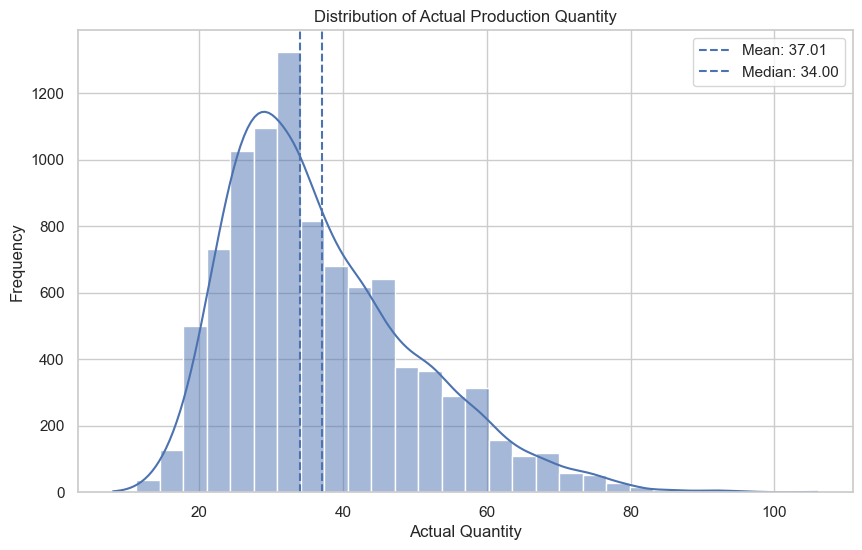

In [23]:
# Distribution of Actual Quantity

plt.figure(figsize=(10, 6))

ax = sns.histplot(
    df['actual_qty'],
    bins=30,
    kde=True
)

mean_val = df['actual_qty'].mean()
median_val = df['actual_qty'].median()

plt.axvline(
    mean_val,
    linestyle='--',
    label=f'Mean: {mean_val:.2f}'
)

plt.axvline(
    median_val,
    linestyle='--',
    label=f'Median: {median_val:.2f}'
)

plt.title('Distribution of Actual Production Quantity')
plt.xlabel('Actual Quantity')
plt.ylabel('Frequency')
plt.legend()
plt.show()

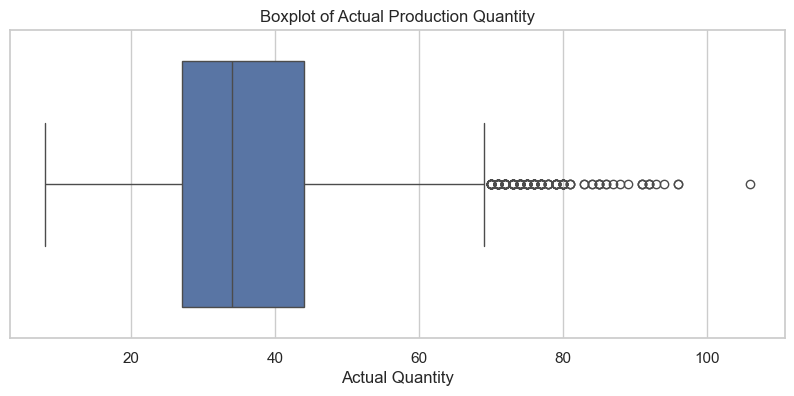

In [24]:
# Boxplot of Actual Quantity

plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df['actual_qty']
)

plt.title('Boxplot of Actual Production Quantity')
plt.xlabel('Actual Quantity')
plt.show()

In [25]:
# Check target percentiles

df['actual_qty'].quantile(
    [0, .01, .05, .10, .25, .50, .75, .90, .95, .99, 1]
)

0.00      8.0
0.01     16.0
0.05     20.0
0.10     23.0
0.25     27.0
0.50     34.0
0.75     44.0
0.90     56.0
0.95     62.0
0.99     74.0
1.00    106.0
Name: actual_qty, dtype: float64

In [26]:
# Create production-volume categories using quartiles

q1 = df['actual_qty'].quantile(0.25)
q2 = df['actual_qty'].quantile(0.50)
q3 = df['actual_qty'].quantile(0.75)

def production_volume_category(x):
    if x <= q1:
        return 'Low Production'
    elif x <= q2:
        return 'Lower-Medium Production'
    elif x <= q3:
        return 'Upper-Medium Production'
    else:
        return 'High Production'

df['production_volume_category'] = (
    df['actual_qty']
    .apply(production_volume_category)
)

df['production_volume_category'].value_counts()

production_volume_category
Low Production             2426
Lower-Medium Production    2418
High Production            2371
Upper-Medium Production    2280
Name: count, dtype: int64

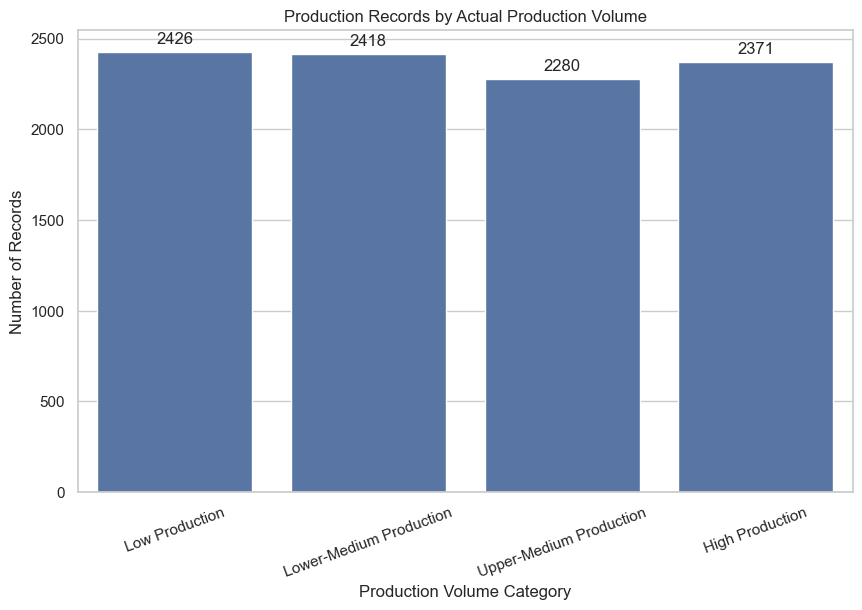

In [27]:
# Plot production-volume categories

order = [
    'Low Production',
    'Lower-Medium Production',
    'Upper-Medium Production',
    'High Production'
]

plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df,
    x='production_volume_category',
    order=order
)

for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}',
        (p.get_x() + p.get_width() / 2.,
         p.get_height()),
        ha='center',
        va='center',
        xytext=(0, 9),
        textcoords='offset points'
    )

plt.title('Production Records by Actual Production Volume')
plt.xlabel('Production Volume Category')
plt.ylabel('Number of Records')
plt.xticks(rotation=20)
plt.show()

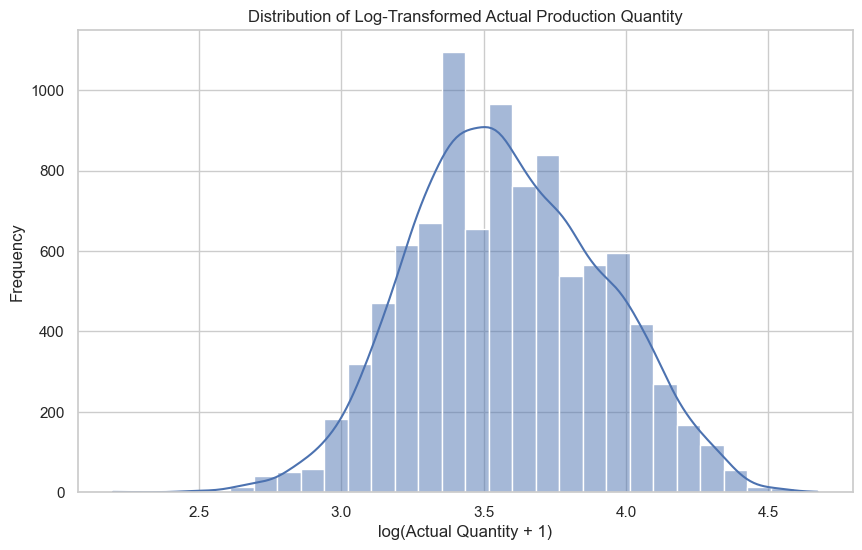

In [28]:
# Log-transformed target distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    np.log1p(df['actual_qty']),
    bins=30,
    kde=True
)

plt.title('Distribution of Log-Transformed Actual Production Quantity')
plt.xlabel('log(Actual Quantity + 1)')
plt.ylabel('Frequency')
plt.show()

# Section 4 — Temporal and Seasonal Analysis

Actual production quantity may vary over time due to changes in production schedules, demand, workforce availability, factory conditions, product mix, machine availability, and operational requirements.

This section examines actual production quantity across:

- Production weeks
- Financial months
- Financial years
- Week numbers
- Week of month

The purpose is to identify temporal patterns that may be useful for forecasting actual production quantity.

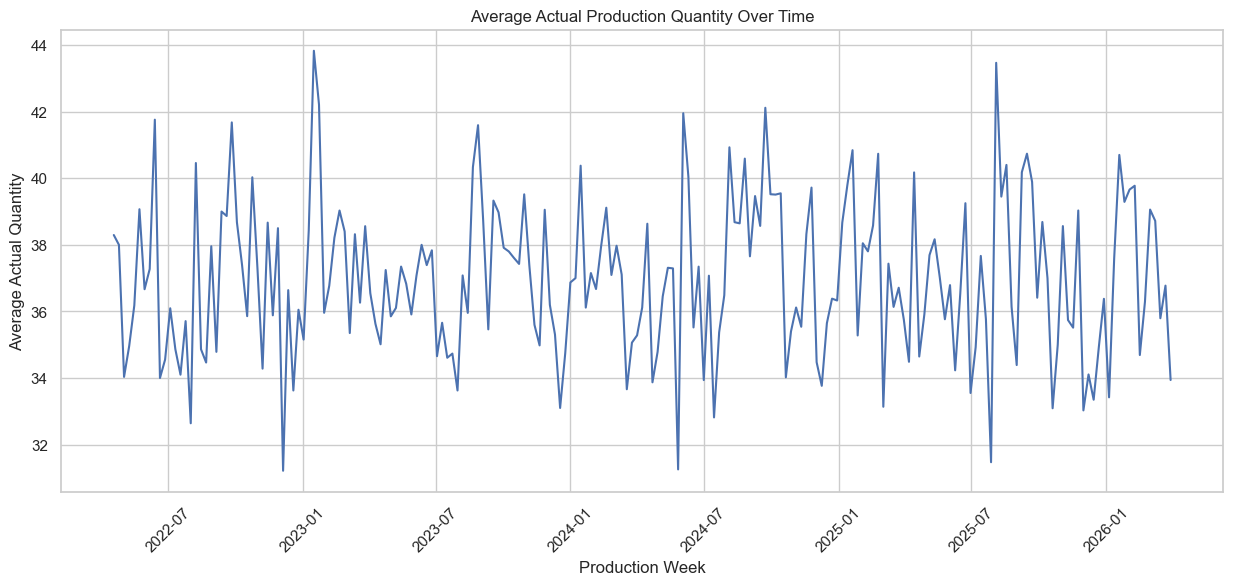

In [29]:
weekly_production = (
    df.groupby('week_start_date')['actual_qty']
      .mean()
      .reset_index()
)

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=weekly_production,
    x='week_start_date',
    y='actual_qty'
)

plt.title('Average Actual Production Quantity Over Time')
plt.xlabel('Production Week')
plt.ylabel('Average Actual Quantity')
plt.xticks(rotation=45)
plt.show()

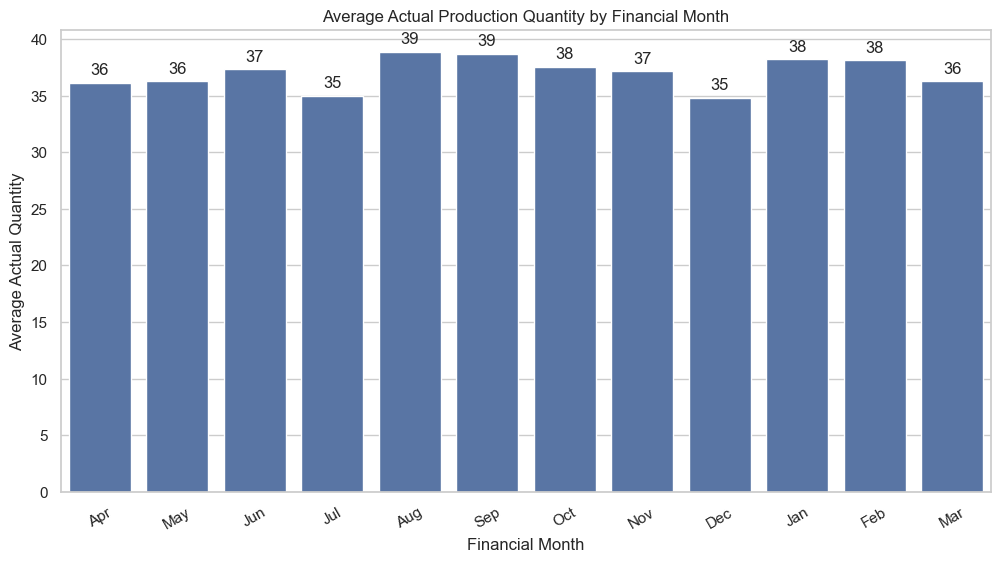

In [30]:
month_order = [
    'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep',
    'Oct', 'Nov', 'Dec', 'Jan', 'Feb', 'Mar'
]

monthly_production = (
    df.groupby('financial_month')['actual_qty']
      .mean()
      .reindex(month_order)
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=monthly_production.index,
    y=monthly_production.values
)

for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.0f}',
        (p.get_x() + p.get_width() / 2.,
         p.get_height()),
        ha='center',
        va='center',
        xytext=(0, 9),
        textcoords='offset points'
    )

plt.title('Average Actual Production Quantity by Financial Month')
plt.xlabel('Financial Month')
plt.ylabel('Average Actual Quantity')
plt.xticks(rotation=30)
plt.show()

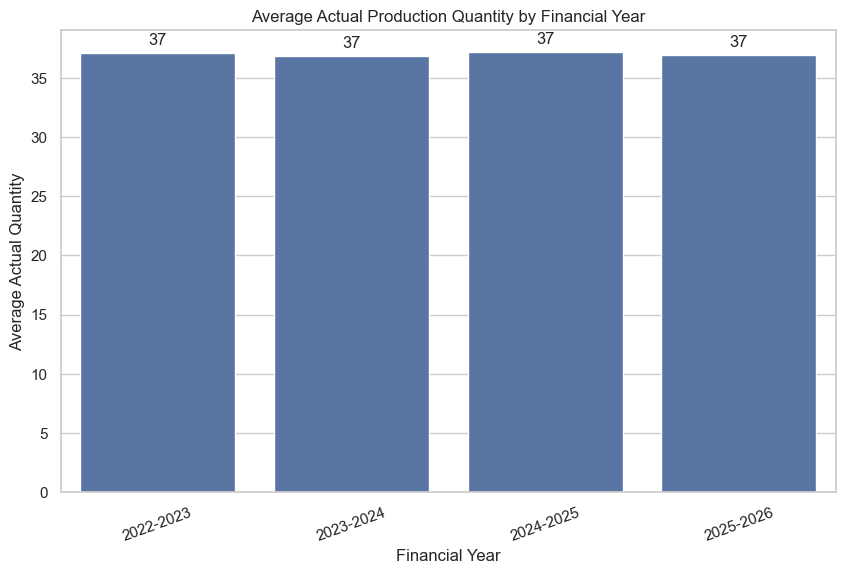

In [31]:
year_production = (
    df.groupby('financial_year')['actual_qty']
      .mean()
      .sort_index()
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=year_production.index,
    y=year_production.values
)

for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.0f}',
        (p.get_x() + p.get_width() / 2.,
         p.get_height()),
        ha='center',
        va='center',
        xytext=(0, 9),
        textcoords='offset points'
    )

plt.title('Average Actual Production Quantity by Financial Year')
plt.xlabel('Financial Year')
plt.ylabel('Average Actual Quantity')
plt.xticks(rotation=20)
plt.show()

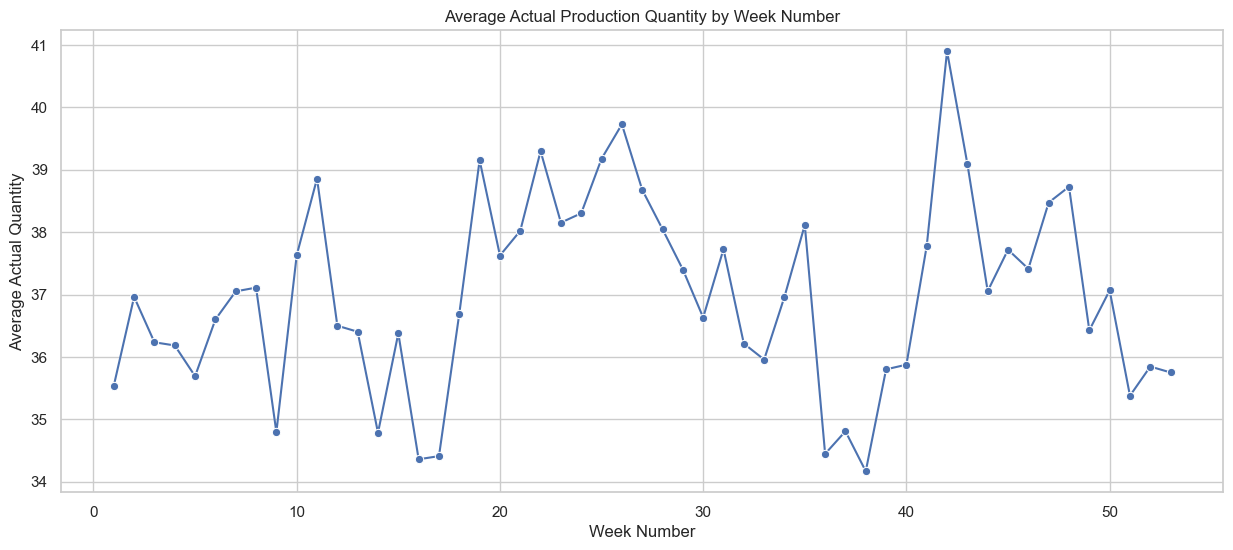

In [32]:
week_production = (
    df.groupby('week_no')['actual_qty']
      .mean()
)

plt.figure(figsize=(15, 6))

sns.lineplot(
    x=week_production.index,
    y=week_production.values,
    marker='o'
)

plt.title('Average Actual Production Quantity by Week Number')
plt.xlabel('Week Number')
plt.ylabel('Average Actual Quantity')
plt.show()

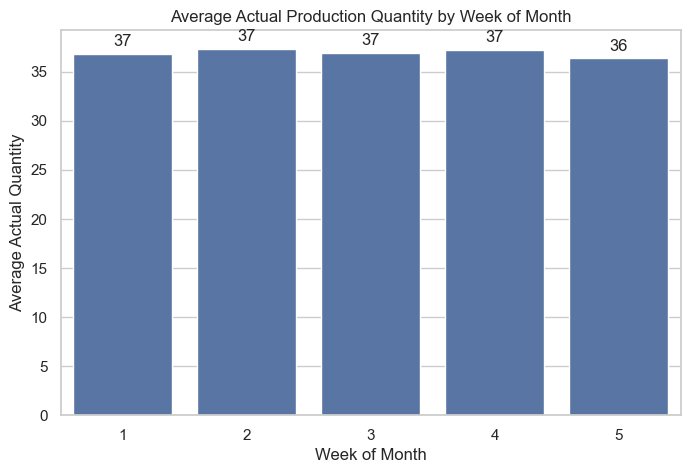

In [33]:
week_month_production = (
    df.groupby('week_of_month')['actual_qty']
      .mean()
)

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=week_month_production.index,
    y=week_month_production.values
)

for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.0f}',
        (p.get_x() + p.get_width() / 2.,
         p.get_height()),
        ha='center',
        va='center',
        xytext=(0, 9),
        textcoords='offset points'
    )

plt.title('Average Actual Production Quantity by Week of Month')
plt.xlabel('Week of Month')
plt.ylabel('Average Actual Quantity')
plt.show()

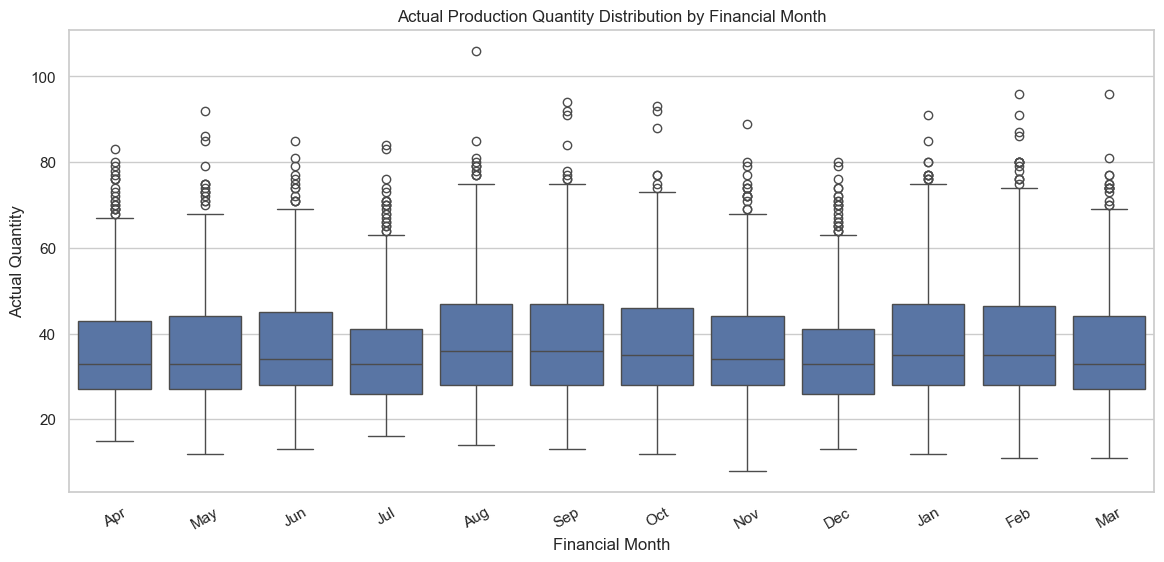

In [34]:
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df,
    x='financial_month',
    y='actual_qty',
    order=month_order
)

plt.title('Actual Production Quantity Distribution by Financial Month')
plt.xlabel('Financial Month')
plt.ylabel('Actual Quantity')
plt.xticks(rotation=30)
plt.show()

# Section 5 — Categorical Features vs Target

Categorical production characteristics may influence actual production quantity through differences in product complexity, customer requirements, production processes, factory conditions, workforce allocation, and operational priorities.

This section evaluates the relationship between categorical variables and the target variable, `actual_qty`.

The analysis focuses on:

- Factory Unit
- Product Family
- Size ID
- Grade
- Order Category
- Bottleneck Flag
- Financial Year
- Financial Month

In [35]:
categorical_features = [
    'factory_unit',
    'product_family',
    'size_id',
    'grade',
    'order_category',
    'bottleneck_flag',
    'financial_year',
    'financial_month'
]

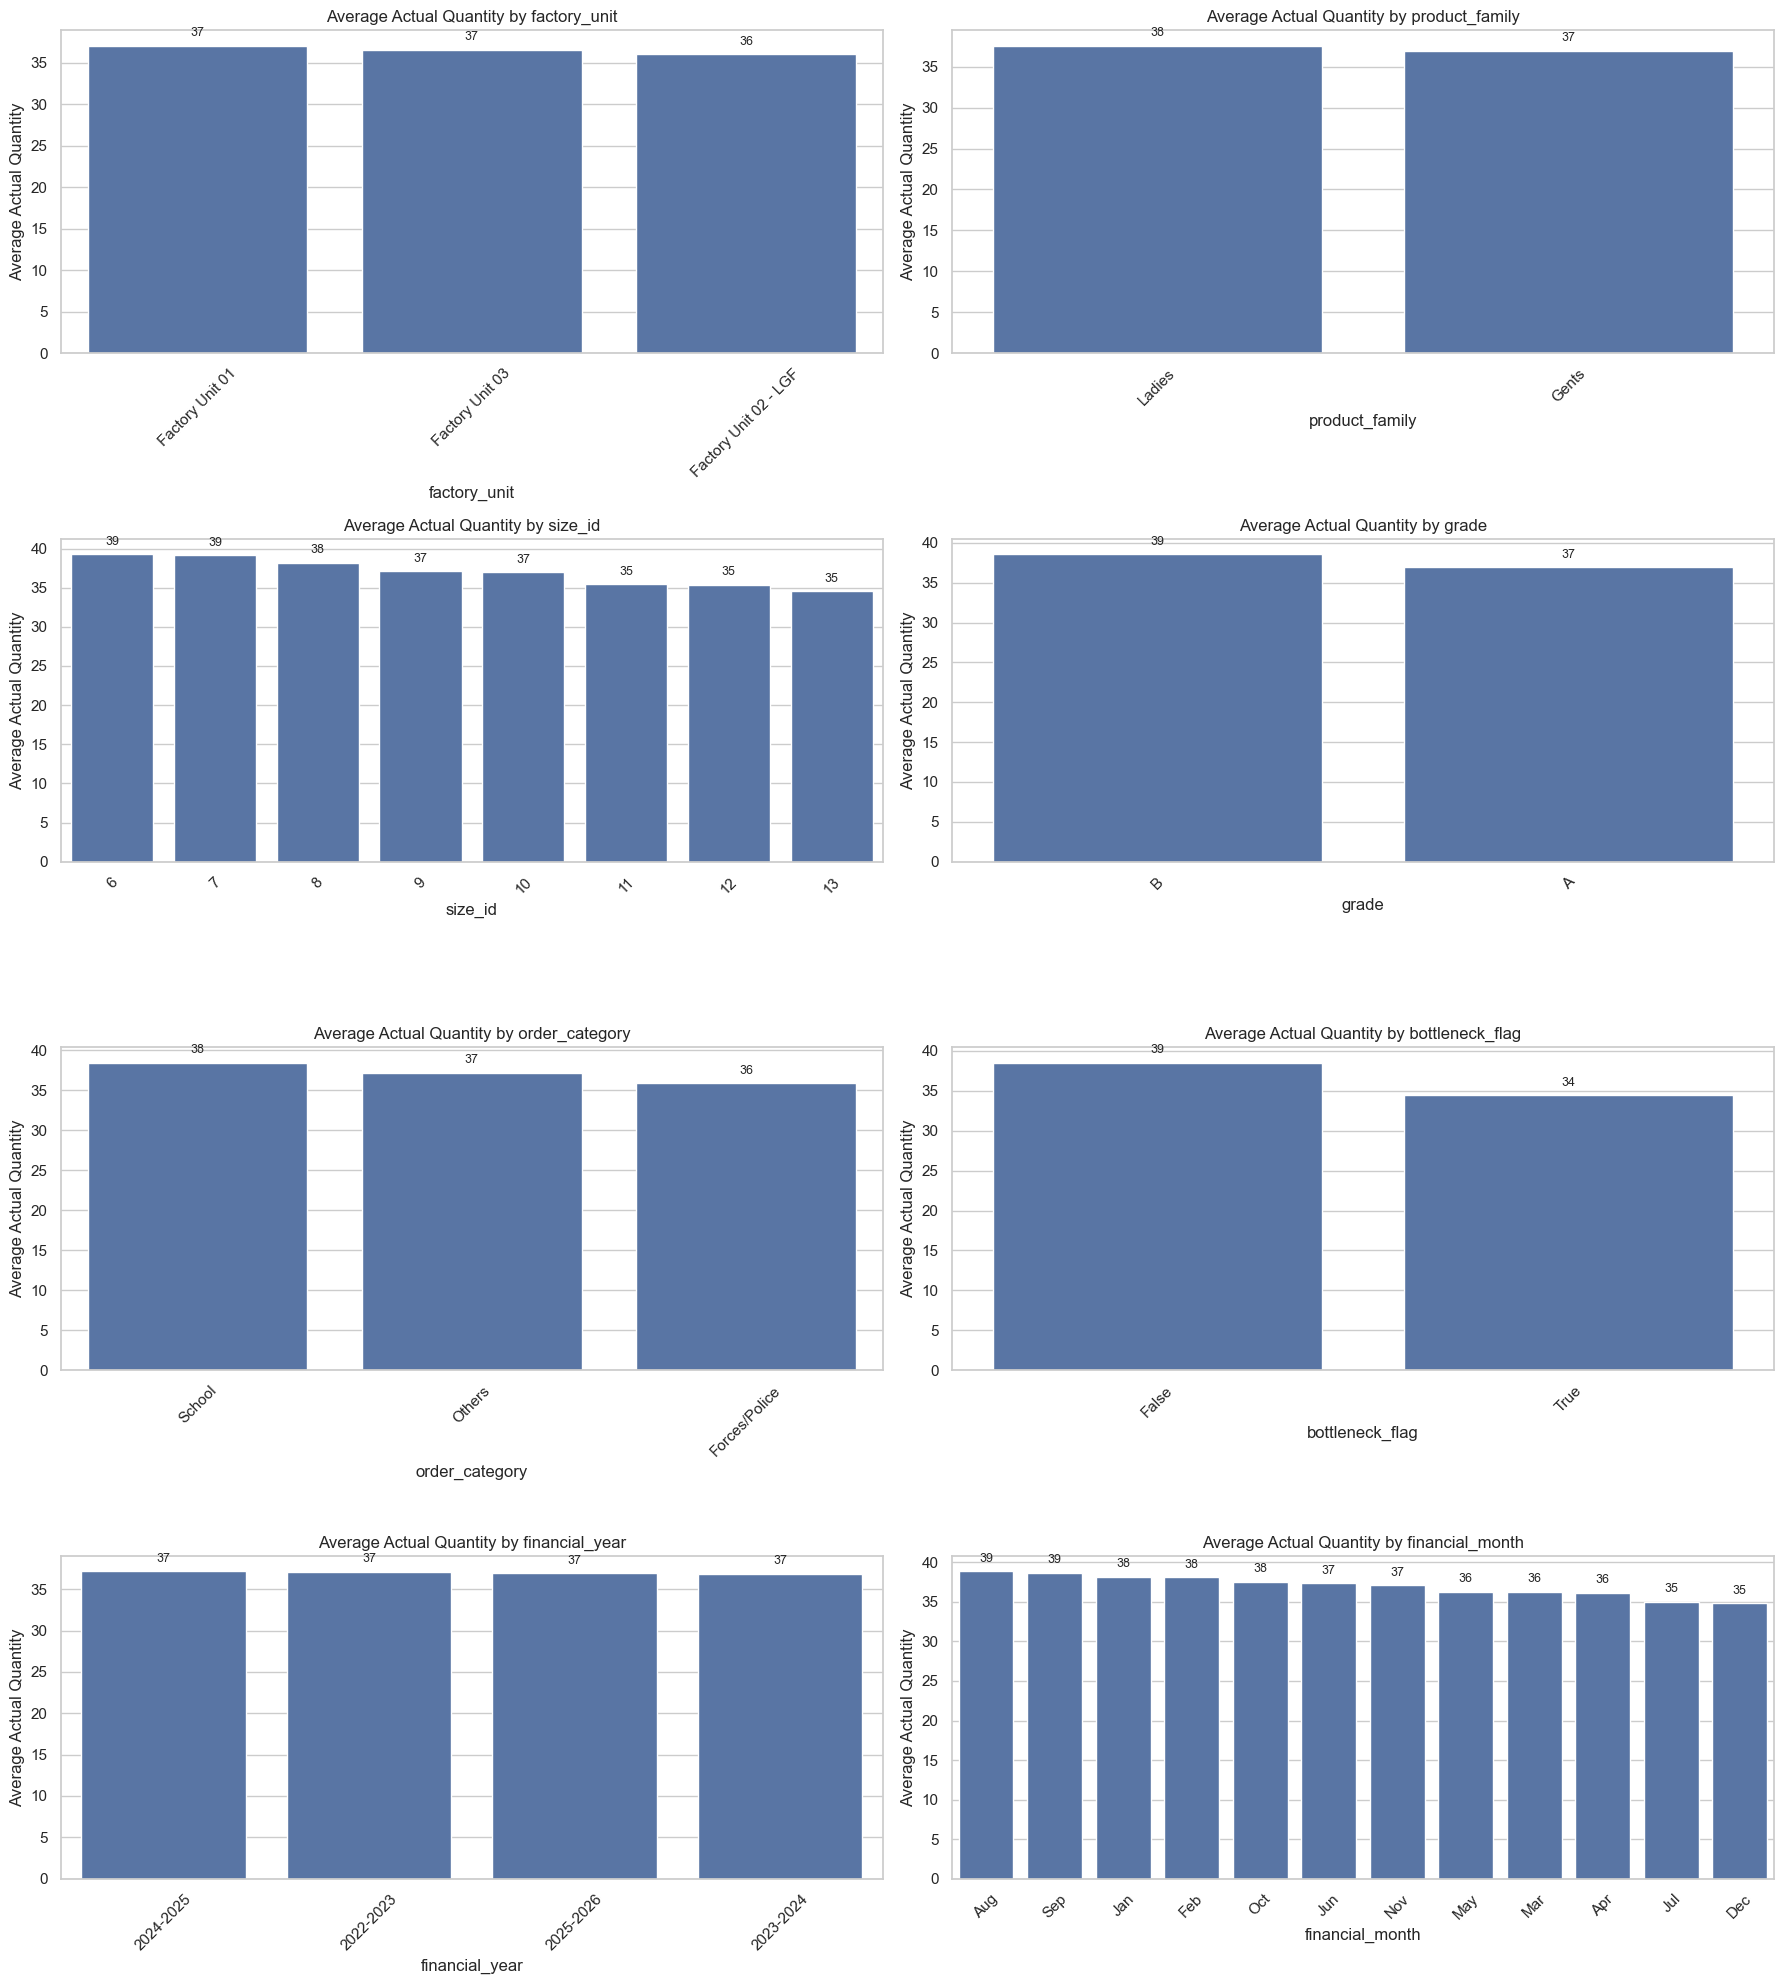

In [36]:
n_features = len(categorical_features)

n_cols = 2
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 5 * n_rows)
)

axes = np.asarray(axes).flatten()

for ax, feature in zip(axes, categorical_features):

    summary = (
        df.groupby(feature)['actual_qty']
          .mean()
          .sort_values(ascending=False)
    )

    sns.barplot(
        x=summary.index.astype(str),
        y=summary.values,
        ax=ax
    )

    for p in ax.patches:
        ax.annotate(
            f'{p.get_height():.0f}',
            (p.get_x() + p.get_width() / 2.,
             p.get_height()),
            ha='center',
            va='center',
            xytext=(0, 9),
            textcoords='offset points',
            fontsize=9
        )

    ax.set_title(
        f'Average Actual Quantity by {feature}'
    )

    ax.set_xlabel(feature)
    ax.set_ylabel('Average Actual Quantity')
    ax.tick_params(axis='x', rotation=45)

for ax in axes[n_features:]:
    ax.remove()

plt.tight_layout()
plt.show()

In [37]:
# Item-level analysis

item_summary = (
    df.groupby('item_name')['actual_qty']
      .agg(['mean', 'count'])
      .sort_values('count', ascending=False)
)

item_summary.head(20)

,mean,count
item_name,,
DIYANA - L - BROWN,37.534884,43
ROGGER - L - BLACK,35.900000,40
BINOLI - BROWN,35.131579,38
D 90 - L - WHITE,37.702703,37
DI SAFETY 551 - L - BROWN,34.810811,37
D 707 - L - BROWN,32.756757,37
D 707 - L - BLACK,32.277778,36
ROMI - L - BLACK,42.694444,36
AYOMI (VAST) - L - BEIGE,39.714286,35


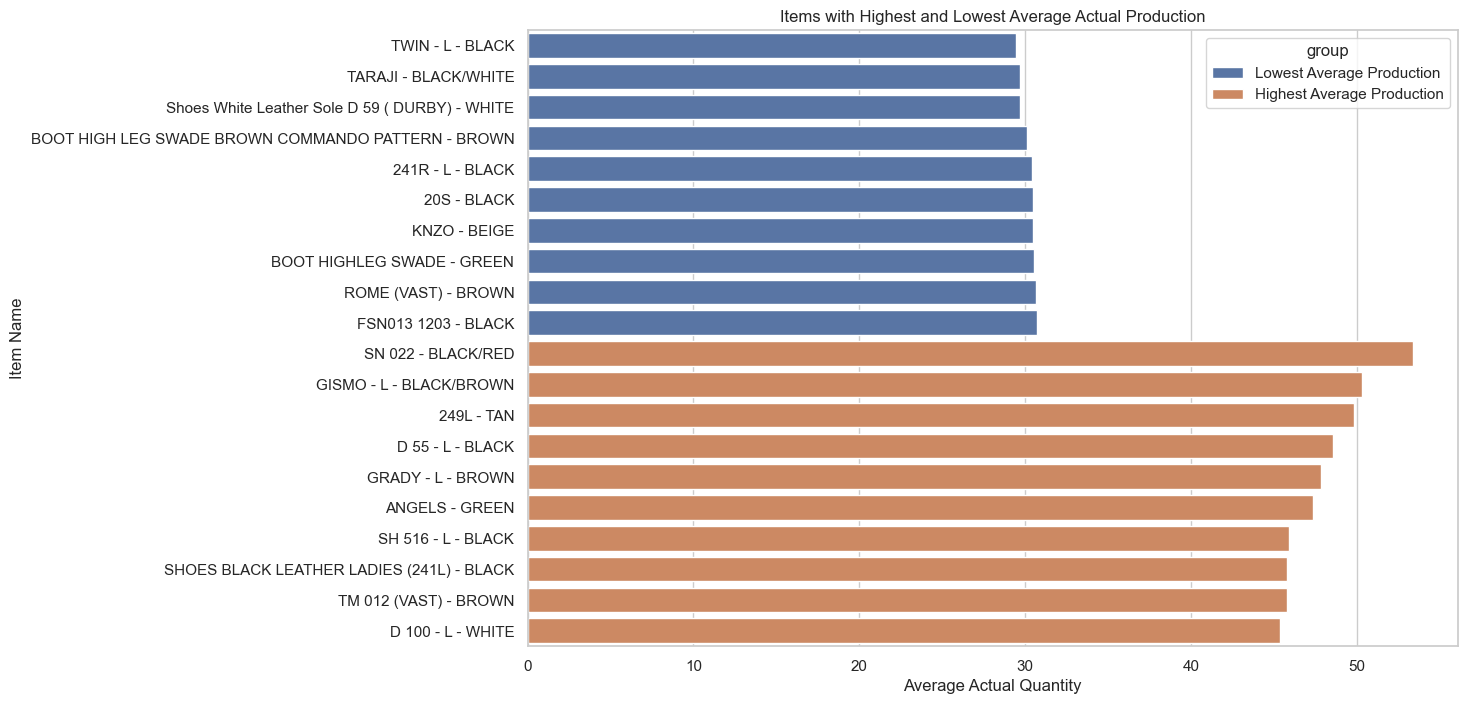

In [38]:
# Consider items with at least 10 observations

item_filtered = item_summary[
    item_summary['count'] >= 10
]

top_items = (
    item_filtered
    .sort_values('mean', ascending=False)
    .head(10)
)

bottom_items = (
    item_filtered
    .sort_values('mean', ascending=True)
    .head(10)
)

item_plot = pd.concat([
    bottom_items.assign(
        group='Lowest Average Production'
    ),
    top_items.assign(
        group='Highest Average Production'
    )
])

plt.figure(figsize=(12, 8))

sns.barplot(
    data=item_plot,
    x='mean',
    y=item_plot.index,
    hue='group'
)

plt.title(
    'Items with Highest and Lowest Average Actual Production'
)

plt.xlabel('Average Actual Quantity')
plt.ylabel('Item Name')
plt.show()

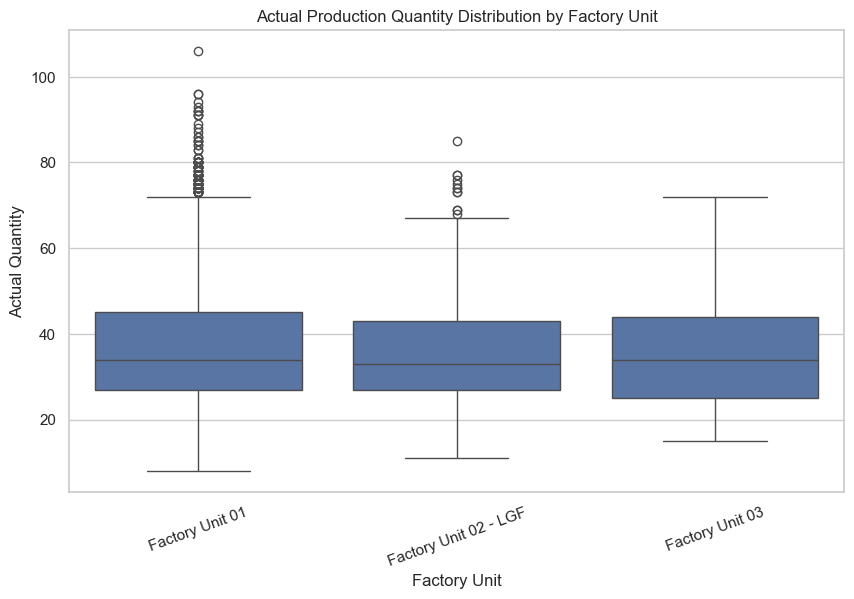

In [39]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='factory_unit',
    y='actual_qty'
)

plt.title('Actual Production Quantity Distribution by Factory Unit')
plt.xlabel('Factory Unit')
plt.ylabel('Actual Quantity')
plt.xticks(rotation=20)
plt.show()

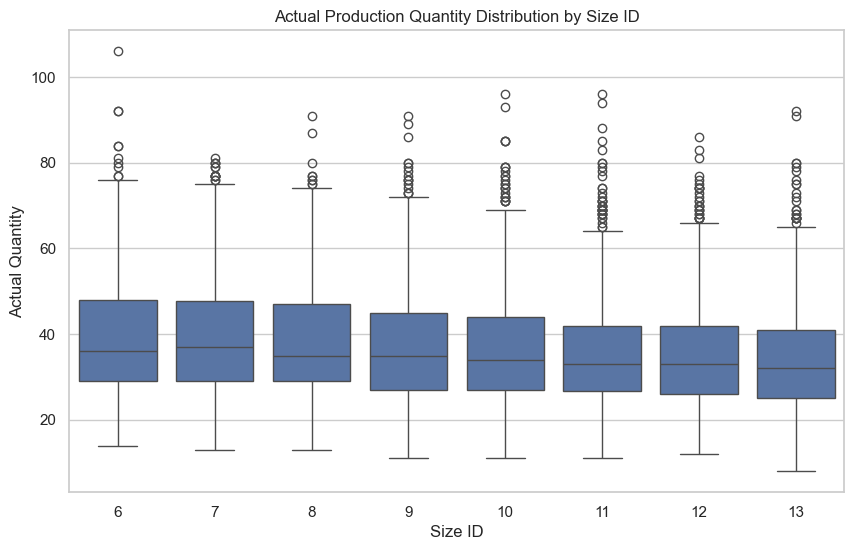

In [40]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='size_id',
    y='actual_qty'
)

plt.title('Actual Production Quantity Distribution by Size ID')
plt.xlabel('Size ID')
plt.ylabel('Actual Quantity')
plt.show()

In [41]:
bottleneck_summary = (
    df.groupby('bottleneck_flag')['actual_qty']
      .agg(['count', 'mean', 'median', 'std'])
)

bottleneck_summary

,count,mean,median,std
bottleneck_flag,,,,
False,5983,38.507271,36.0,13.127614
True,3512,34.464692,32.0,12.518350


## Section 6 — Numerical Features vs Target

This section investigates the relationships between numerical production-planning and operational variables and the target variable, `actual_qty`.

The analysis focuses only on variables that are available in the current cleaned dataset and that can potentially be known before the final actual production quantity is observed.

Variables directly derived from `actual_qty` are excluded because they would introduce target leakage.

These include:

- `actual_value`
- `production_gap_qty`
- `production_gap_value`
- `qty_per_labor_hour`
- `qty_per_machine_hour`
- `cycle_time_mins`
- `achievement_ratio`

The target variable `actual_qty` is not used as an input feature.

In [42]:
# Candidate numerical features
candidate_numeric_features = [
    'planned_qty',
    'monthly_plan_qty',
    'rate',
    'no_of_workers',
    'labor_hours',
    'overtime_hours',
    'working_hours',
    'machine_capacity_per_day',
    'machine_count',
    'total_duration_per_shoe_mins',
    'takt_time_mins',
    'week_no',
    'week_of_month'
]

# Keep only columns that actually exist in the current dataset
numeric_features = [
    col for col in candidate_numeric_features
    if col in df.columns
]

print("Numerical features available for EDA:")
print(numeric_features)

print("\nColumns not available in the current dataset:")
print([
    col for col in candidate_numeric_features
    if col not in df.columns
])

Numerical features available for EDA:
['planned_qty', 'rate', 'no_of_workers', 'working_hours', 'machine_capacity_per_day', 'machine_count', 'total_duration_per_shoe_mins', 'week_no', 'week_of_month']

Columns not available in the current dataset:
['monthly_plan_qty', 'labor_hours', 'overtime_hours', 'takt_time_mins']


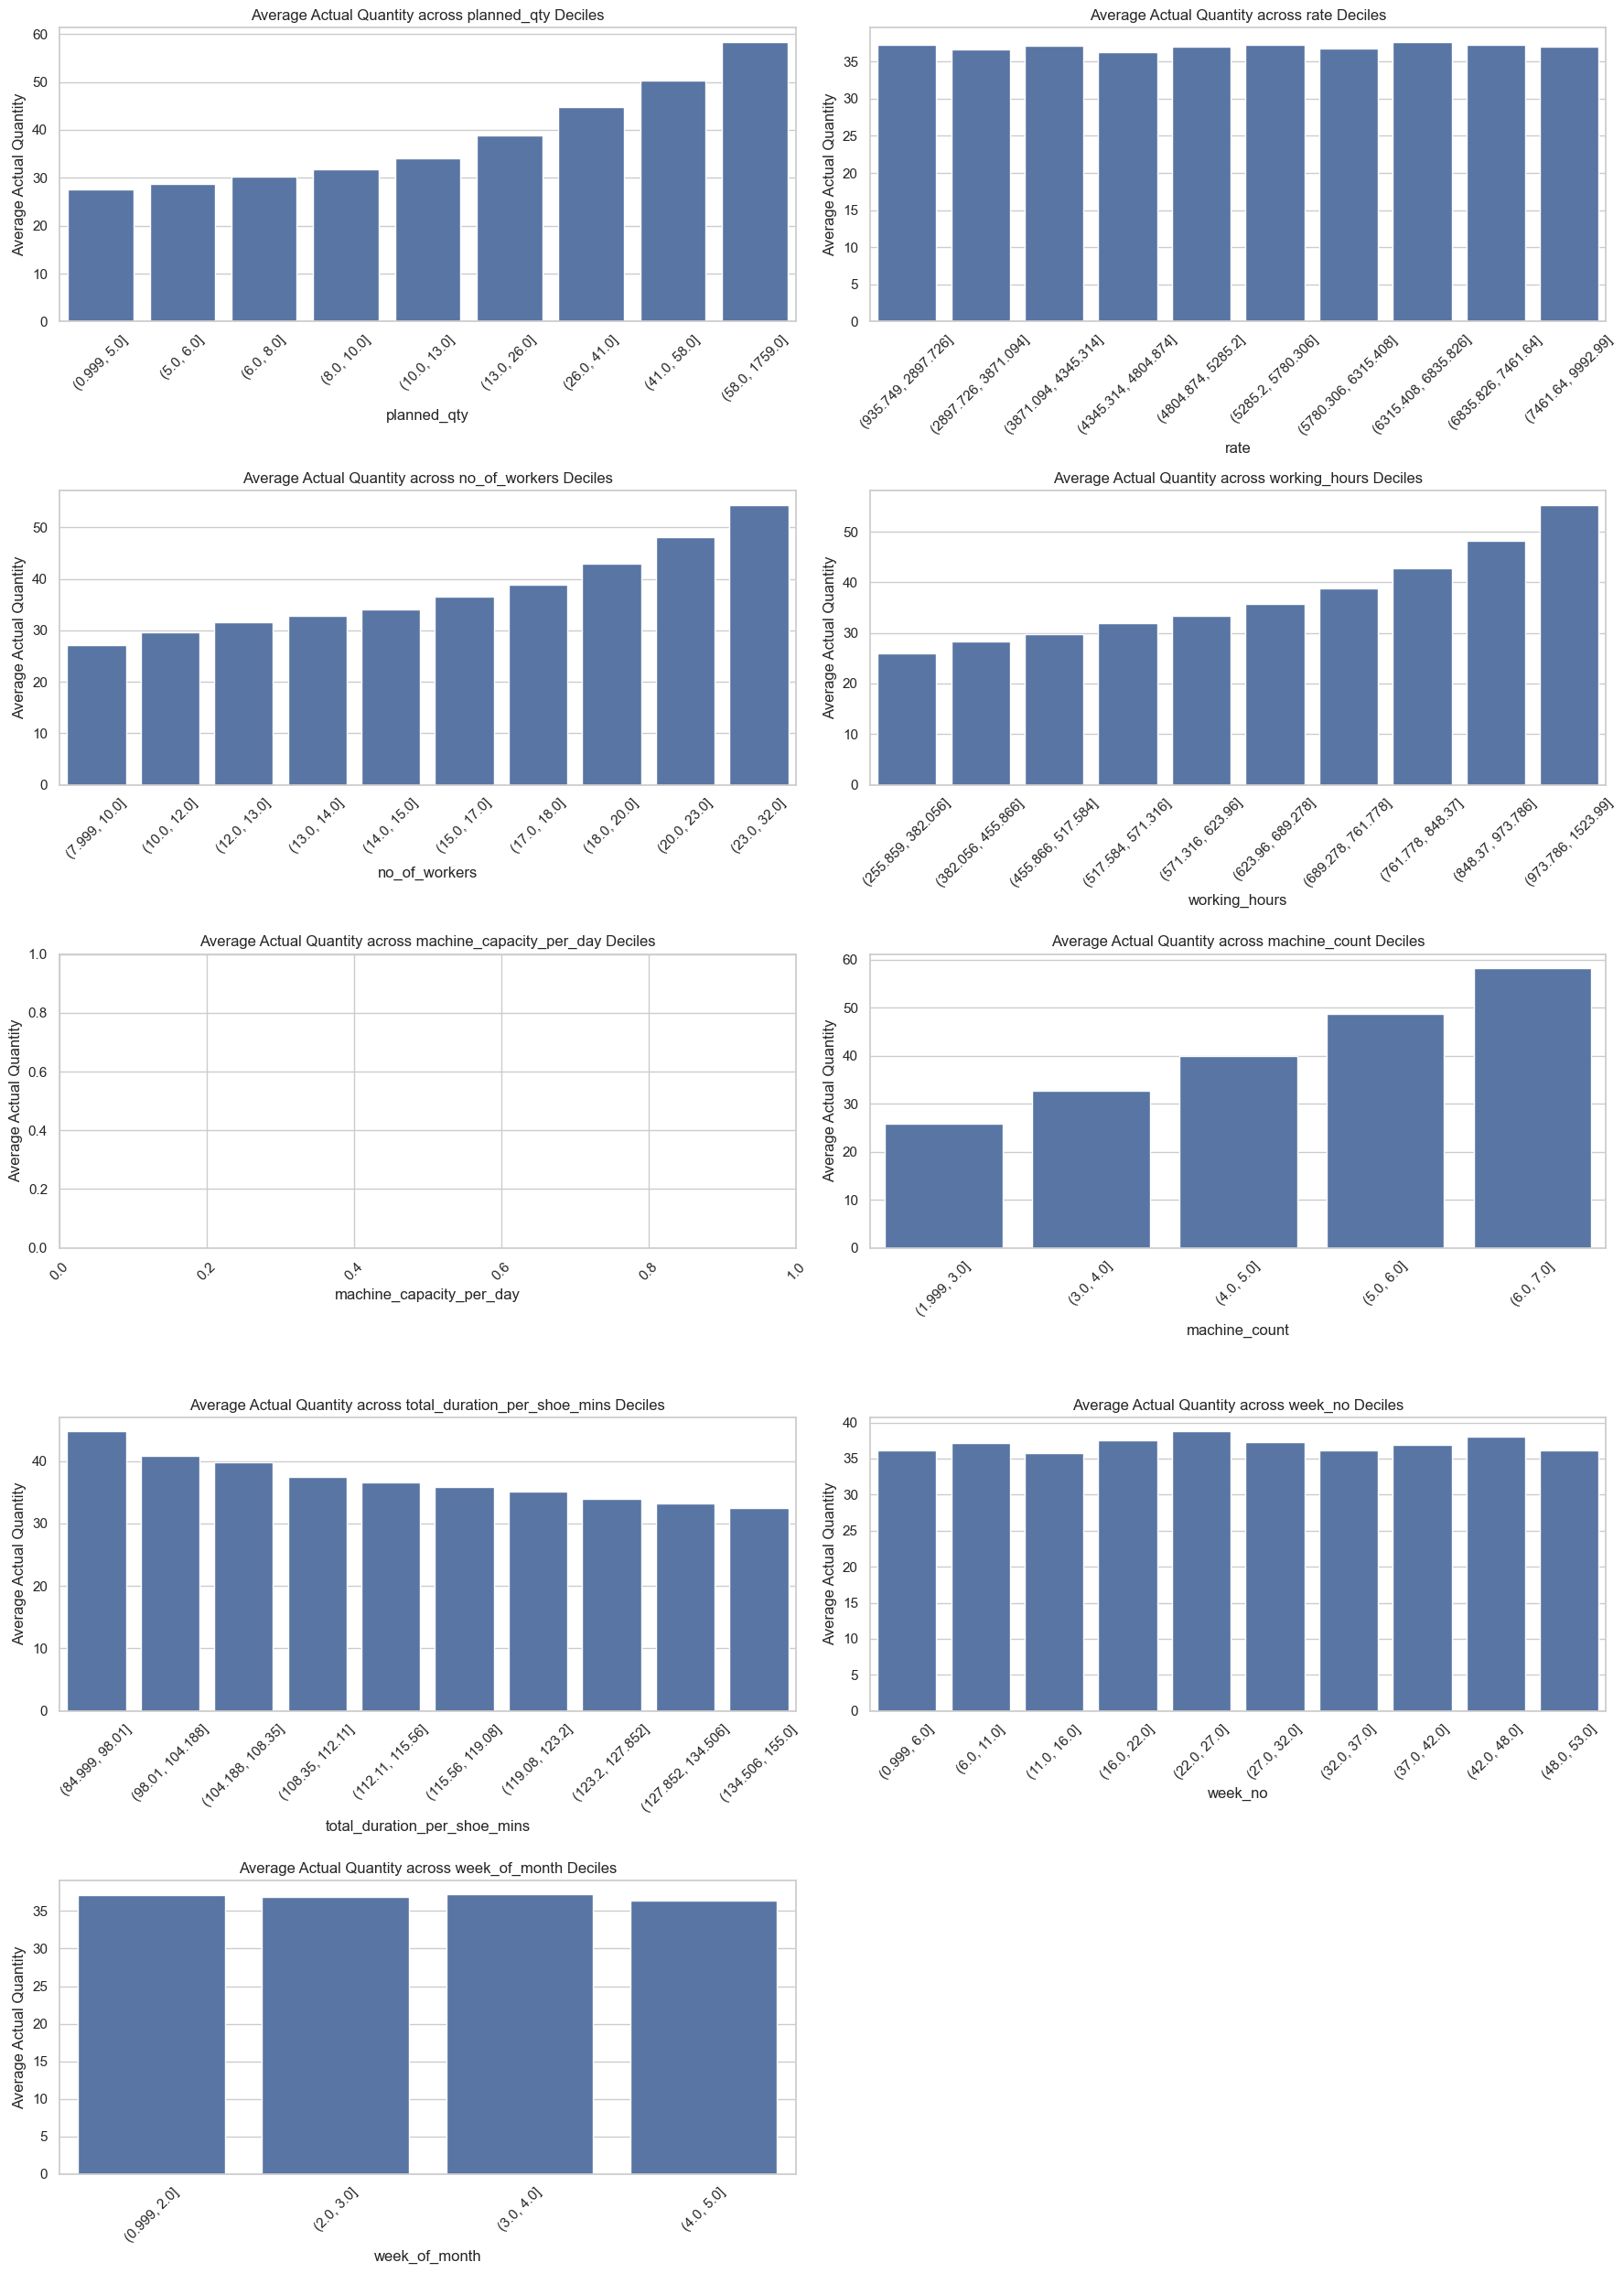

In [43]:
n_features = len(numeric_features)

n_cols = 2
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 5 * n_rows)
)

axes = np.asarray(axes).flatten()

for ax, feature in zip(axes, numeric_features):

    temp = df[
        [feature, 'actual_qty']
    ].dropna().copy()

    try:
        temp['bin'] = pd.qcut(
            temp[feature],
            q=10,
            duplicates='drop'
        )

        summary = (
            temp.groupby(
                'bin',
                observed=True
            )['actual_qty']
            .mean()
        )

        sns.barplot(
            x=summary.index.astype(str),
            y=summary.values,
            ax=ax
        )

        ax.set_title(
            f'Average Actual Quantity across {feature} Deciles'
        )

        ax.set_xlabel(feature)
        ax.set_ylabel('Average Actual Quantity')

        ax.tick_params(
            axis='x',
            rotation=45
        )

    except ValueError:

        ax.scatter(
            temp[feature],
            temp['actual_qty'],
            alpha=0.35
        )

        ax.set_title(
            f'{feature} vs Actual Quantity'
        )

        ax.set_xlabel(feature)
        ax.set_ylabel('Actual Quantity')

for ax in axes[n_features:]:
    ax.remove()

plt.tight_layout()
plt.show()

# Section 7 — Correlation Analysis

Correlation analysis is performed to examine the strength and direction of linear relationships between the numerical variables and the target variable, `actual_qty`.

The Pearson correlation coefficient is used for this analysis.

The correlation coefficient ranges from -1 to +1:

- **+1** indicates a strong positive linear relationship.
- **-1** indicates a strong negative linear relationship.
- **0** indicates little or no linear relationship.

The analysis is used to identify potentially influential numerical variables and to detect highly correlated predictors that may create redundancy or multicollinearity during model development.

Variables that are directly derived from the target variable are excluded from the correlation analysis to avoid target leakage. These include `actual_value`, `production_gap_qty`, `production_gap_value`, `achievement_ratio`, `qty_per_labor_hour`, `qty_per_machine_hour`, and `cycle_time_mins`.

It should be noted that correlation measures only linear relationships. Therefore, a low correlation does not necessarily mean that a variable has no predictive value, as machine learning models can capture nonlinear relationships and interactions.

In [44]:
# Numerical features selected for correlation analysis
correlation_features = [
    col for col in numeric_features
    if col in df.columns and col != 'actual_qty'
]

# Include the target variable
correlation_columns = correlation_features + ['actual_qty']

# Create correlation matrix
correlation_matrix = df[correlation_columns].corr()

print("Variables included in correlation analysis:")
print(correlation_columns)

Variables included in correlation analysis:
['planned_qty', 'rate', 'no_of_workers', 'working_hours', 'machine_capacity_per_day', 'machine_count', 'total_duration_per_shoe_mins', 'week_no', 'week_of_month', 'actual_qty']


In [45]:
correlation_matrix.round(3)

,planned_qty,rate,no_of_workers,working_hours,machine_capacity_per_day,machine_count,total_duration_per_shoe_mins,week_no,week_of_month,actual_qty
planned_qty,1.000,0.005,0.379,0.405,NaN,0.290,-0.002,0.001,-0.008,0.432
rate,0.005,1.000,-0.001,-0.003,NaN,0.011,-0.016,-0.063,0.004,0.007
no_of_workers,0.379,-0.001,1.000,0.970,NaN,0.413,0.316,0.008,-0.003,0.624
working_hours,0.405,-0.003,0.970,1.000,NaN,0.432,0.313,0.006,-0.001,0.683
machine_capacity_per_day,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
machine_count,0.290,0.011,0.413,0.432,NaN,1.000,-0.016,0.018,0.004,0.690
total_duration_per_shoe_mins,-0.002,-0.016,0.316,0.313,NaN,-0.016,1.000,-0.001,-0.003,-0.272
week_no,0.001,-0.063,0.008,0.006,NaN,0.018,-0.001,1.000,0.066,0.015
week_of_month,-0.008,0.004,-0.003,-0.001,NaN,0.004,-0.003,0.066,1.000,-0.002
actual_qty,0.432,0.007,0.624,0.683,NaN,0.690,-0.272,0.015,-0.002,1.000


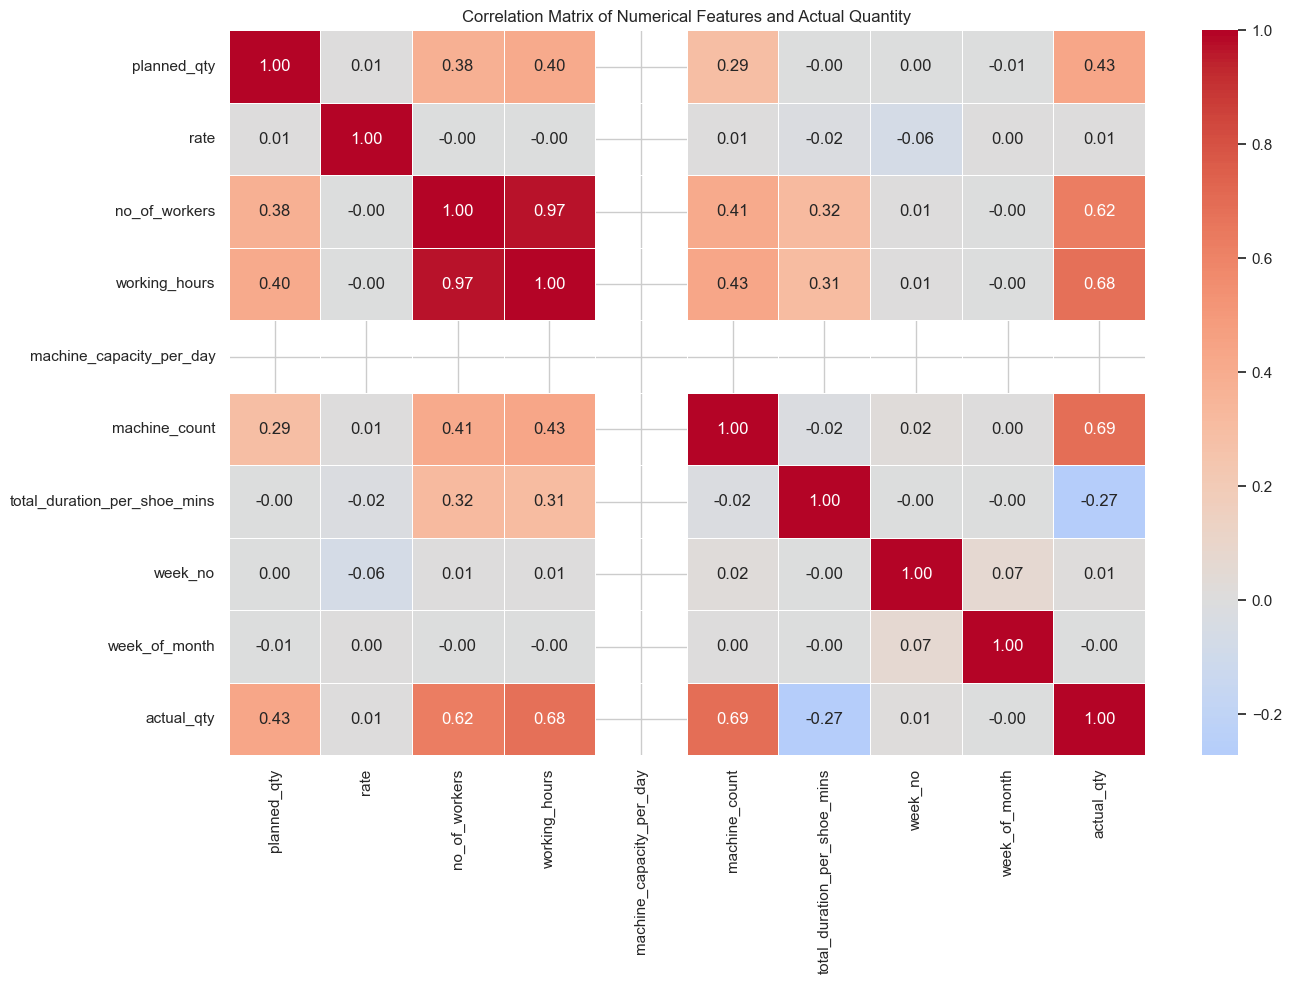

In [46]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features and Actual Quantity")
plt.tight_layout()
plt.show()

In [47]:
target_correlations = (
    correlation_matrix['actual_qty']
    .drop('actual_qty')
    .sort_values(ascending=False)
)

print("Correlation of Numerical Features with Actual Quantity:")
display(target_correlations.to_frame(name='Correlation with actual_qty'))

Correlation of Numerical Features with Actual Quantity:


,Correlation with actual_qty
machine_count,0.689623
working_hours,0.682933
no_of_workers,0.623795
planned_qty,0.431519
week_no,0.014598
rate,0.006793
week_of_month,-0.001624
total_duration_per_shoe_mins,-0.272027
machine_capacity_per_day,NaN


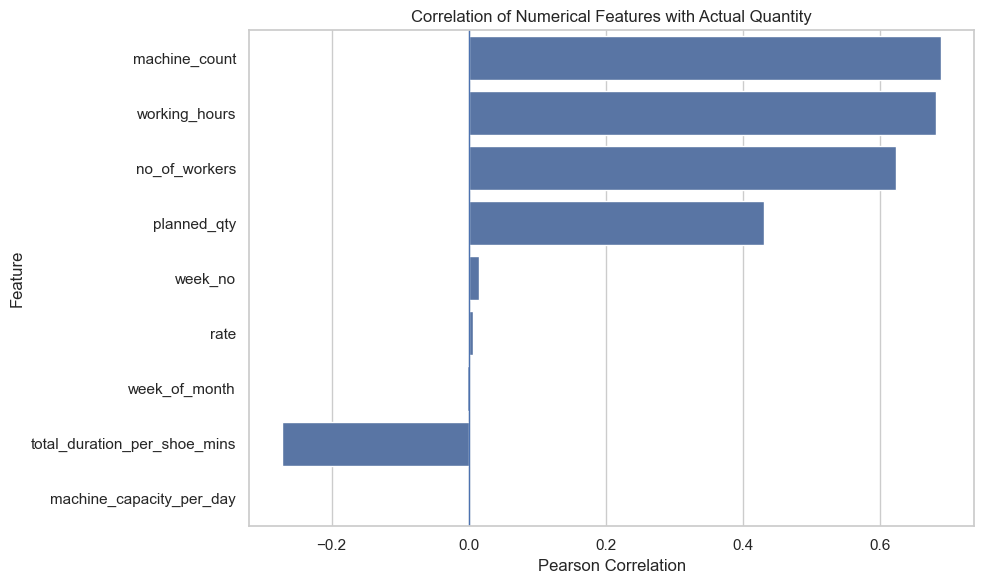

In [48]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=target_correlations.values,
    y=target_correlations.index
)

plt.axvline(0, linewidth=1)

plt.title("Correlation of Numerical Features with Actual Quantity")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [49]:
# Correlation among predictor variables only
predictor_corr = df[correlation_features].corr().abs()

# Select upper triangle of correlation matrix
upper_triangle = predictor_corr.where(
    np.triu(
        np.ones(predictor_corr.shape),
        k=1
    ).astype(bool)
)

# Identify pairs with correlation greater than 0.80
high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    'Feature 1',
    'Feature 2',
    'Absolute Correlation'
]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs['Absolute Correlation'] >= 0.80
].sort_values(
    'Absolute Correlation',
    ascending=False
)

print("Highly correlated predictor pairs (|r| >= 0.80):")

display(high_corr_pairs)

Highly correlated predictor pairs (|r| >= 0.80):


,Feature 1,Feature 2,Absolute Correlation
13,no_of_workers,working_hours,0.969682


# Section 8 — Key Insights and Modelling Implications

The exploratory data analysis provides several important findings that will guide the subsequent feature engineering and machine learning stages.

## 8.1 Target Variable

The target variable for the predictive modelling stage is `actual_qty`, representing the actual quantity of shoes produced.

The target was changed from `achievement_ratio` to `actual_qty` because `achievement_ratio` is mathematically derived from both `actual_qty` and `planned_qty`:

`achievement_ratio = actual_qty / planned_qty`

Using `planned_qty` as an input feature while predicting `achievement_ratio` creates a direct mathematical dependency between the target and one of the predictors. Therefore, predicting `actual_qty` provides a more appropriate modelling formulation.

The predicted actual quantity can subsequently be compared with `planned_qty` to calculate the expected production achievement and production gap.

## 8.2 Planning Quantity as an Important Input

`planned_qty` represents the expected production requirement for the week and is available as an input before production occurs.

Its relationship with `actual_qty` is therefore particularly important for forecasting how much production can realistically be achieved.

## 8.3 Temporal Patterns

The analysis of financial years, financial months, weeks, and weeks of the month indicates that production levels vary over time.

These patterns suggest that calendar-based features may provide useful information for the predictive model.

Potential features for later modelling include:

- Financial year
- Financial month
- Week number
- Week of month
- Week start date
- Derived calendar features

## 8.4 Categorical Factors

Production levels vary across factory units, product families, product categories, grades, and other categorical characteristics.

Bottleneck-related differences are also important because production conditions associated with bottlenecks can affect the quantity that is ultimately produced.

These categorical variables should therefore be considered during feature engineering and model development.

## 8.5 Numerical Relationships

The numerical analysis shows that some variables have stronger relationships with `actual_qty` than others.

However, correlation alone should not be used to determine feature importance because machine learning models can capture nonlinear relationships and interactions between variables.

Therefore, variables with relatively weak individual correlations may still contribute useful predictive information when combined with other features.

## 8.6 Multicollinearity and Redundant Variables

Some operational variables may be strongly correlated with one another because they describe related aspects of the same production process.

For example, working hours and labour hours may contain overlapping information.

Highly correlated predictors should therefore be reviewed during feature engineering and model development to reduce unnecessary redundancy.

## 8.7 Target Leakage Considerations

Variables that are calculated using `actual_qty` must not be used as predictors when forecasting `actual_qty`.

These include:

- `actual_value`
- `production_gap_qty`
- `production_gap_value`
- `achievement_ratio`
- `qty_per_labor_hour`
- `qty_per_machine_hour`
- `cycle_time_mins`

Including these variables would allow the model to indirectly access information about the target and would result in misleadingly high model performance.

## 8.8 Machine Capacity

`machine_capacity_per_day` was identified during preprocessing as having zero variance across the dataset.

Since a variable with no variation cannot explain differences in the target, it is not useful as a conventional predictive feature and has therefore been excluded from modelling.

## 8.9 Implications for Machine Learning

The EDA suggests that actual production quantity is influenced by a combination of:

- Production planning requirements
- Factory characteristics
- Product characteristics
- Labour resources
- Machine resources
- Process-time characteristics
- Bottleneck conditions
- Temporal patterns

Therefore, the modelling stage should evaluate both linear and nonlinear regression models.

Candidate models include:

- Linear Regression
- Random Forest Regressor
- Gradient Boosting Regressor
- XGBoost Regressor
- Support Vector Regression

A chronological train-test split should be used rather than random shuffling because the objective is to predict future production quantities using information available before production.

Model performance will be evaluated using:

- Mean Absolute Error (MAE)
- Root Mean Square Error (RMSE)
- R² Score

## 8.10 From Predicted Actual Quantity to Production Achievement

Although `actual_qty` is now the primary machine learning target, the original business objective of measuring production achievement can still be retained.

After obtaining the predicted actual quantity:

`Predicted Achievement Ratio = Predicted Actual Quantity / Planned Quantity`

The expected production gap can then be calculated as:

`Expected Production Gap = Planned Quantity - Predicted Actual Quantity`

This allows the predictive model to support the original production-planning objective without creating circularity in the target definition.

## 8.11 Overall EDA Conclusion

The EDA indicates that weekly actual production quantity is influenced by multiple operational, planning, product, factory, and temporal factors.

The findings provide a foundation for feature engineering and machine learning model development.

The next stage will focus on preparing leakage-free predictive features, engineering appropriate temporal and operational variables, applying a chronological train-test split, developing regression models, and evaluating their ability to forecast actual weekly production quantity.